# Lab 1 &ndash; Running Grover on Qiskit

Please indicate here the names of the coworkers on this notebook:

- Cyprien Kelma
- Paul Pousset
- Nathan Eudeline

## A) Introduction to Qiskit

So far we used IBM Q's Composer interface to construct, execute and simulate quantum circuits, but the [Qiskit](https://www.ibm.com/quantum/qiskit) library provides a much more versatile and powerful way to manipulate these from a Jupyter notebook such as this one. You can run it locally on your computer by making sure you have the `qiskit`, `qiskit-aer` and `qiskit-ibm-runtime` libraries installed or in an online environement such as Google Colab (more details [here](https://docs.quantum.ibm.com/guides/install-qiskit)).

So make sure you have the Qiskit library for Python installed, then start by importing the features we will be using today:

In [1]:
# In your Python (<=3.13 at time of writing) environment:
# pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib

from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_state_city, plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import Aer
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

Let us start by recreating one of our simplest circuits:

In [2]:
circ = QuantumCircuit(2)  # create a circuit with 2 qubits, q_0 and q_1
circ.h(0)                 # apply an H-gate on q_0
circ.cx(0,1)              # apply an X-gate on q_1 controlled by q_0
circ.draw()               # render the circuit visually

┌───┐ 
q_0: ┤ H ├──■──
 └───┘┌─┴─┐
q_1: ─────┤ X ├
 └───┘

Take a moment to make sure you make sense of what each of the lines above achieves (and of course feel free to experiment!). For more information, you can consult the [Qiskit documentation](https://docs.quantum.ibm.com/api/qiskit/circuit_library) for available gates.

The final quantum state of the circuit can be obtained by sending it to the `statevector_simulator`:

In [3]:
state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ)
answer = job.result().get_statevector()
answer

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


Here you can see that the quantum state of the 2-qubit system (initialized at $|00\rangle$) is &ndash; as it should! &ndash; the Bell state

$$ |\psi\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}. $$

Another way to visualize the output is to look instead at the _density matrix_ $\rho = |\psi\rangle \langle\psi|$ of the output state (the probabilities of measuring each basis state can be read from the diagonal of the matrix):
$$ \rho = \begin{bmatrix} \frac{1}{2} & 0 & 0 & \frac{1}{2} \\ 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 \\ \frac{1}{2} & 0 & 0 & \frac{1}{2} \end{bmatrix}. $$

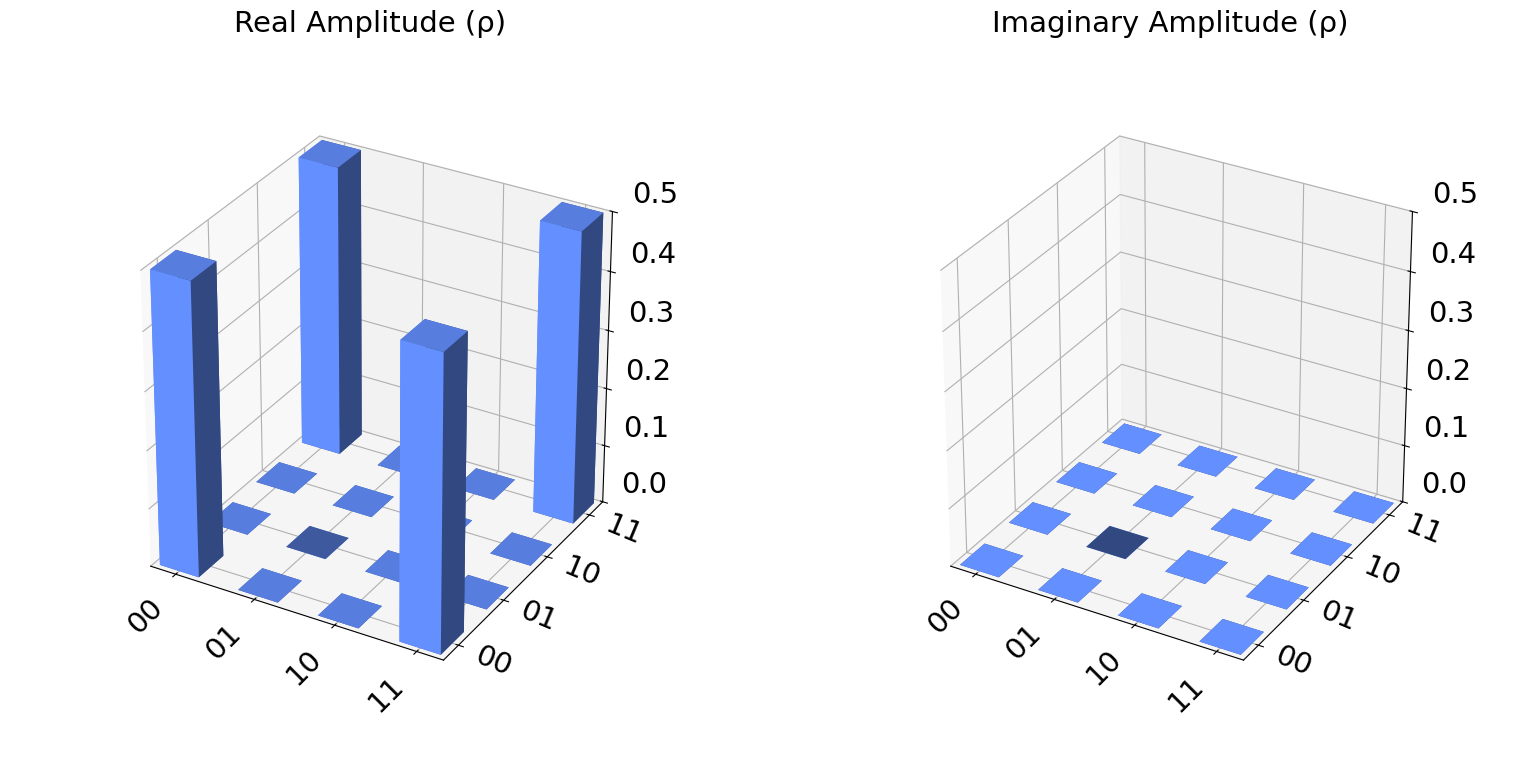

In [4]:
plot_state_city(answer)

If one wants to prepare the qubits in other initial states, it could be useful to turn out circuit into a function that can be used to easily append the required gates to a given circuit.

In [5]:
def bell(qc):
    qc.h(0)
    qc.cx(0,1)

In [6]:
init_circ = QuantumCircuit(2)
init_circ.x(0)
init_circ.barrier()
bell(init_circ)
init_circ.draw()

┌───┐ ░ ┌───┐ 
q_0: ┤ X ├─░─┤ H ├──■──
 └───┘ ░ └───┘┌─┴─┐
q_1: ──────░──────┤ X ├
 ░ └───┘

This initializes the qubits in the $|01\rangle$ state (remember that here $q_0$ comes _last_) and runs them through our circuit. You could then recover the output state by the above procedure as we did in class. 

Note: you can also easily recover the global unitary matrix corresponding to the quantum circuit by sending it to the `unitary_simulator`.

In [7]:
unit_simulator = Aer.get_backend('unitary_simulator')

job = unit_simulator.run(circ)

job.result().get_unitary()

Operator([[ 0.70710678+0.00000000e+00j,  0.70710678-8.65956056e-17j,
            0.        +0.00000000e+00j,  0.        +0.00000000e+00j],
          [ 0.        +0.00000000e+00j,  0.        +0.00000000e+00j,
            0.70710678+0.00000000e+00j, -0.70710678+8.65956056e-17j],
          [ 0.        +0.00000000e+00j,  0.        +0.00000000e+00j,
            0.70710678+0.00000000e+00j,  0.70710678-8.65956056e-17j],
          [ 0.70710678+0.00000000e+00j, -0.70710678+8.65956056e-17j,
            0.        +0.00000000e+00j,  0.        +0.00000000e+00j]],
         input_dims=(2, 2), output_dims=(2, 2))


 **To do**: construct the following circuit
 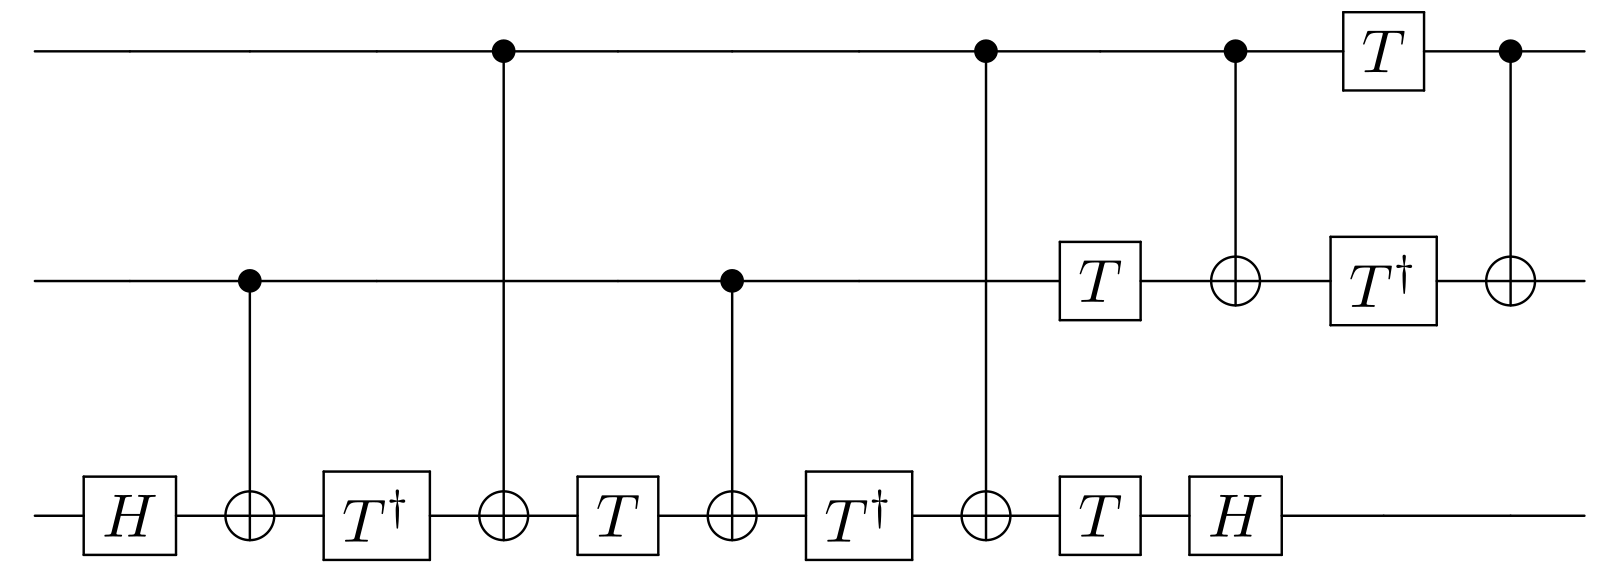
 
 where $T = P(\frac{\pi}{4}) = \begin{bmatrix} 1 & 0 \\ 0 & e^{i \frac{\pi}{4}} \end{bmatrix}$ (directly available as a `t` gate, whereas its inverse $T^\dagger = P(-\frac{\pi}{4})$ is `tdg`).
 
 Write down its $8 \times 8$ unitary matrix representation. Do you recognize this $3$-qubit gate? Try to confirm your answer.

      ░                                              ░            ┌───┐      
q_0: ─░────────────────────■─────────────────────■───░────────■───┤ T ├───■──
      ░                    │                     │   ░ ┌───┐┌─┴─┐┌┴───┴┐┌─┴─┐
q_1: ─░────────■───────────┼─────────■───────────┼───░─┤ T ├┤ X ├┤ Tdg ├┤ X ├
      ░ ┌───┐┌─┴─┐┌─────┐┌─┴─┐┌───┐┌─┴─┐┌─────┐┌─┴─┐ ░ ├───┤├───┤└─────┘└───┘
q_2: ─░─┤ H ├┤ X ├┤ Tdg ├┤ X ├┤ T ├┤ X ├┤ Tdg ├┤ X ├─░─┤ T ├┤ H ├────────────
      ░ └───┘└───┘└─────┘└───┘└───┘└───┘└─────┘└───┘ ░ └───┘└───┘            

This circuit implements a Toffoli (CCX) gate!
Matrices are equal (within numerical precision): True


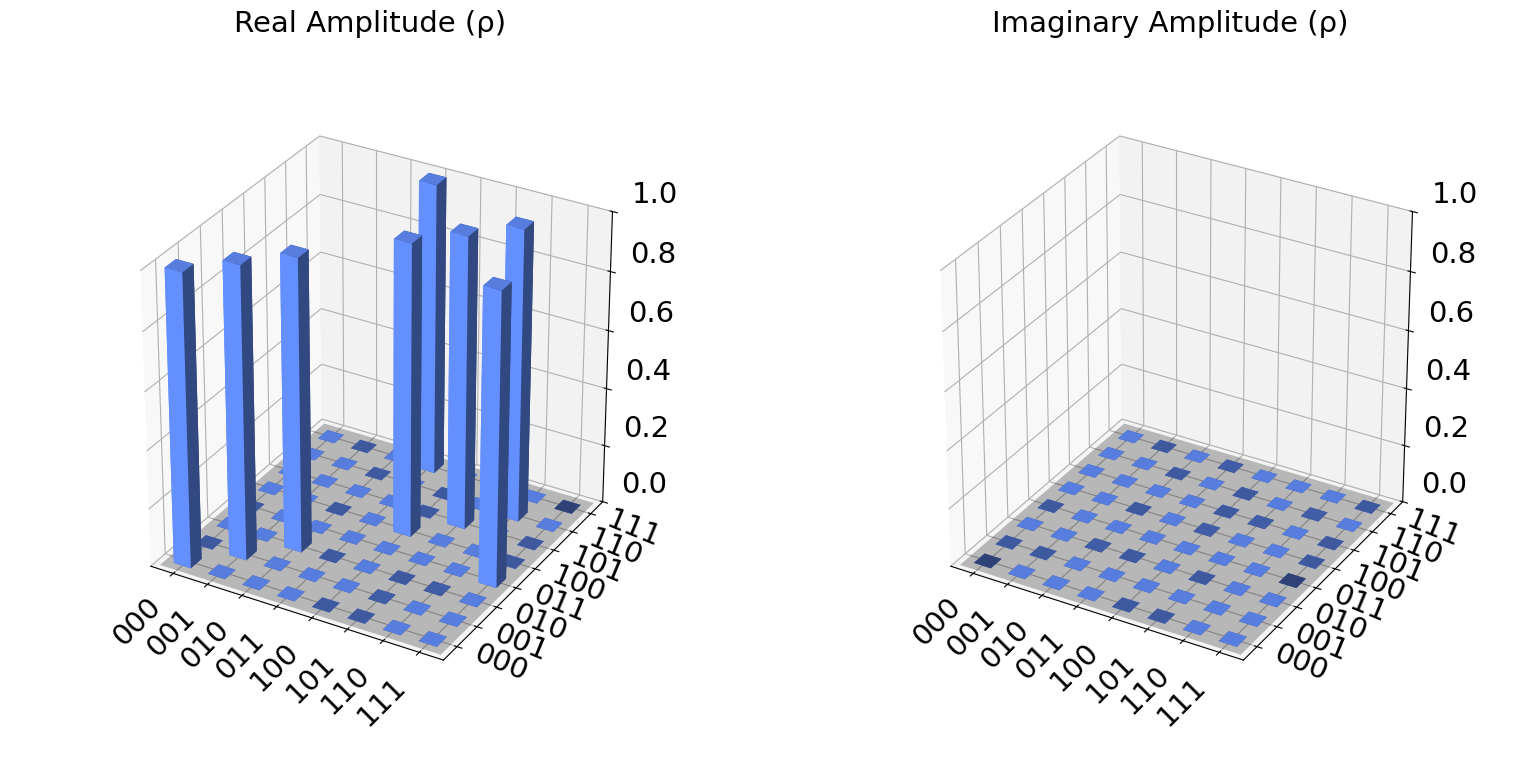

In [8]:
exo_circ = QuantumCircuit(3)
exo_circ.barrier()
exo_circ.h(2)
exo_circ.cx(1,2)
exo_circ.tdg(2)
exo_circ.cx(0,2)
exo_circ.t(2)
exo_circ.cx(1,2)
exo_circ.tdg(2)
exo_circ.cx(0,2)
exo_circ.barrier()
exo_circ.t(1)
exo_circ.t(2)
exo_circ.cx(0,1)
exo_circ.h(2)
exo_circ.t(0)
exo_circ.tdg(1)
exo_circ.cx(0,1)

print(exo_circ.draw())

job_exo = unit_simulator.run(exo_circ)
exo_matrix = job_exo.result().get_unitary()

# Compare with the Toffoli (CCX) gate
toffoli_circ = QuantumCircuit(3)
toffoli_circ.ccx(0, 1, 2)  # Toffoli gate: controlled-controlled-X

job_toffoli = unit_simulator.run(toffoli_circ)
toffoli_matrix = job_toffoli.result().get_unitary()

import numpy as np
print("\nThis circuit implements a Toffoli (CCX) gate!")
print(f"Matrices are equal (within numerical precision): {np.allclose(exo_matrix, toffoli_matrix)}")

plot_state_city(exo_matrix)

## B) Grover with $N = 4$

Let us implement Grover's search algorithm in a space of size $N = 4$ (hence written on $n = 2$ qubits). Suppose to fix ideas we want to find the element $\omega = 10$ in the set $X = \{00, 01, 10, 11\}$.

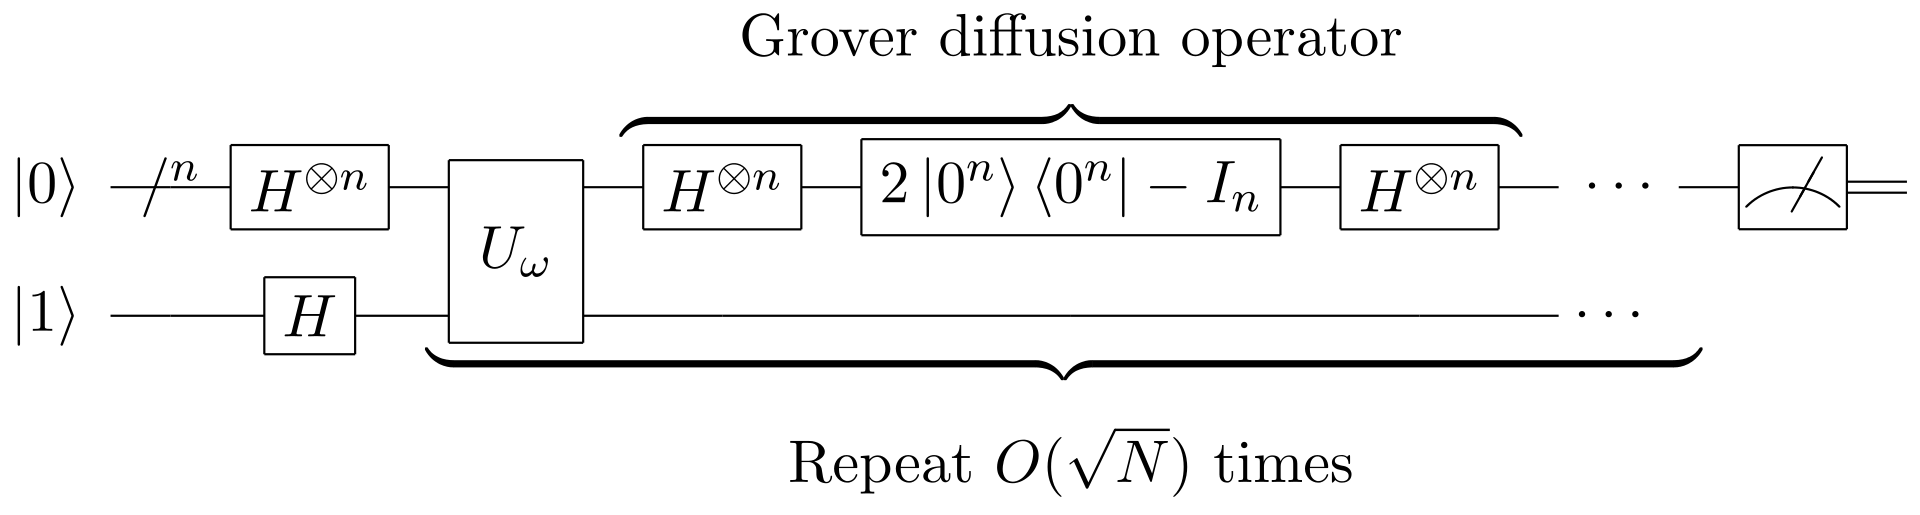

In this situation, we are able to construct directly the phase-flip oracle $U_w$ without the need of an ancillary qubit, so let us just get rid of it. The first thing we need to do is intialize our first 2 qubits to the equal superposition state

$$ |s\rangle = \frac{|00\rangle + |01\rangle + |10\rangle + |11\rangle}{2}. $$

In [9]:
def full_h(qc):
    for i in range(qc.num_qubits):
        qc.h(i)

In [10]:
circ = QuantumCircuit(2)
full_h(circ)
circ.draw()

┌───┐
q_0: ┤ H ├
 ├───┤
q_1: ┤ H ├
 └───┘

For $n = 2$, the equal superposition state $|s\rangle$ makes an initial angle $\frac{\theta}{2} = \arcsin \frac{1}{\sqrt{4}} = \arcsin \frac{1}{2} = \frac{\pi}{6}$ with the horizontal $|s'\rangle$ in the plan spanned by $|s\rangle$ and $|\omega\rangle$. After one rotation of $\theta = \frac{\pi}{3}$, an angle of $\frac{\pi}{2}$ is reached so the state will be exactly $|\omega\rangle$ after a single iteration of the phase amplification stage.

So we only need to apply the $U_\omega$ phase flip oracle, to invert the phase of $|10\rangle$ and leave the 3 other basis vectors untouched. You may check that this can be achieved using a combination of $X$ and controlled-$Z$ gates:

In [11]:
def oracle(qc):
    qc.x(0)
    qc.cz(0,1)
    qc.x(0)

In [12]:
circ.barrier()
oracle(circ)
circ.draw()

┌───┐ ░ ┌───┐ ┌───┐
q_0: ┤ H ├─░─┤ X ├─■─┤ X ├
 ├───┤ ░ └───┘ │ └───┘
q_1: ┤ H ├─░───────■──────
 └───┘ ░

We then need to apply the $U_s = H^{\otimes 2} \, U_0 \, H^{\otimes 2}$ reflection operator (the global sign can be safely discarded). Again $U_0$ can be achieved using a combination of $X$ and $CZ$ gates.

In [13]:
def full_x(qc):
    for i in range(qc.num_qubits):
        qc.x(i)

def g(qc):
    # Hadamard gates
    full_h(qc)
    # U_0
    full_x(qc)
    qc.cz(0,1)
    full_x(qc)
    # Hadamard gates
    full_h(qc)

In [14]:
circ.barrier()
g(circ)
circ.draw()

┌───┐ ░ ┌───┐ ┌───┐ ░ ┌───┐┌───┐ ┌───┐┌───┐
q_0: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├
 ├───┤ ░ └───┘ │ └───┘ ░ ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├─░───────■───────░─┤ H ├┤ X ├─■─┤ X ├┤ H ├
 └───┘ ░ ░ └───┘└───┘ └───┘└───┘

We can confirm that the output state should be $|10\rangle$ with probability 1:

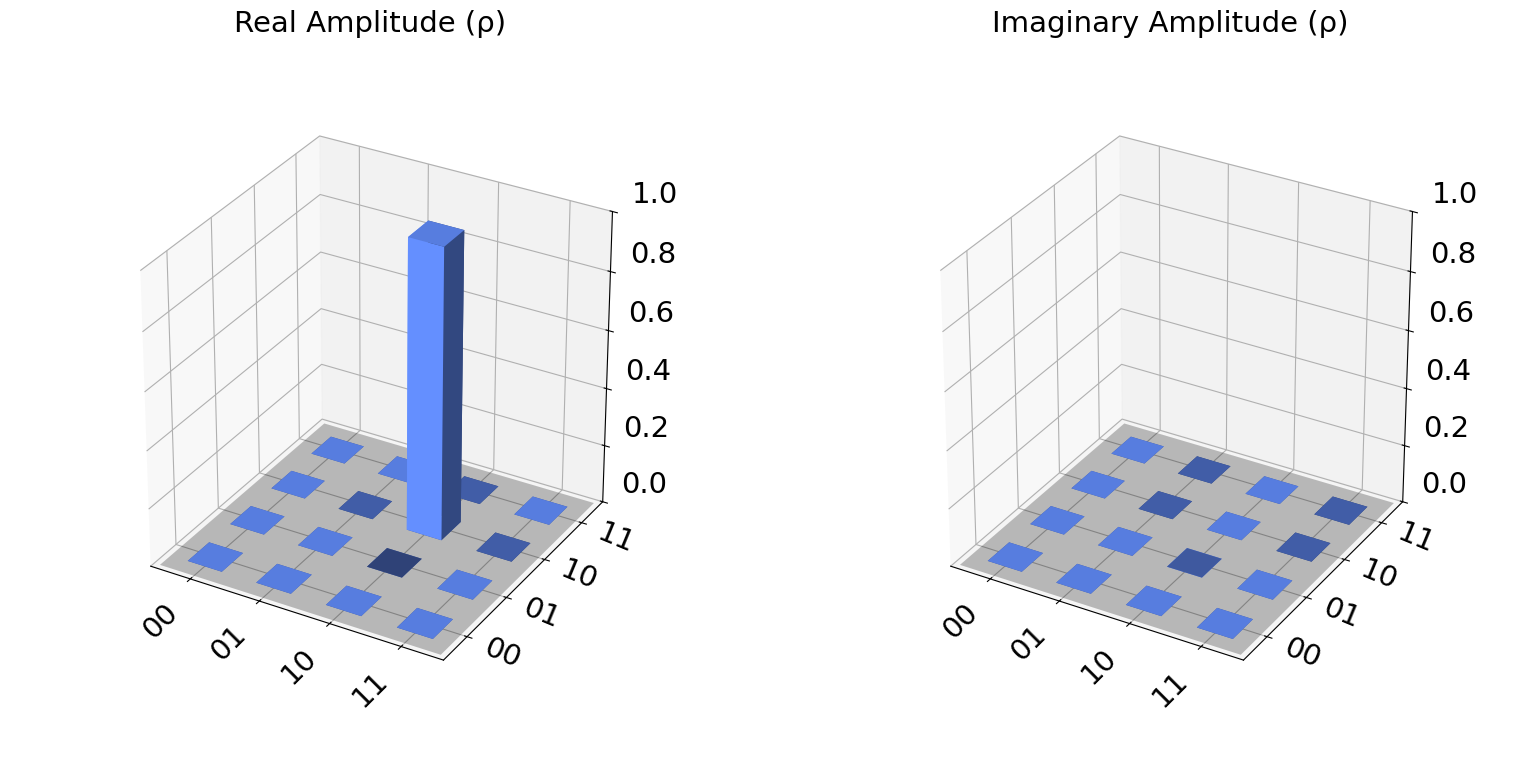

In [15]:
state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ)
answer = job.result().get_statevector()

plot_state_city(answer)

Let us now add measurements and _simulate_ the execution of the algorithm:

In [16]:
circ.measure_all()
circ.draw()

┌───┐ ░ ┌───┐ ┌───┐ ░ ┌───┐┌───┐ ┌───┐┌───┐ ░ ┌─┐ 
 q_0: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░─┤M├───
 ├───┤ ░ └───┘ │ └───┘ ░ ├───┤├───┤ │ ├───┤├───┤ ░ └╥┘┌─┐
 q_1: ┤ H ├─░───────■───────░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──╫─┤M├
 └───┘ ░ ░ └───┘└───┘ └───┘└───┘ ░ ║ └╥┘
meas: 2/═══════════════════════════════════════════════════╩══╩═
 0 1

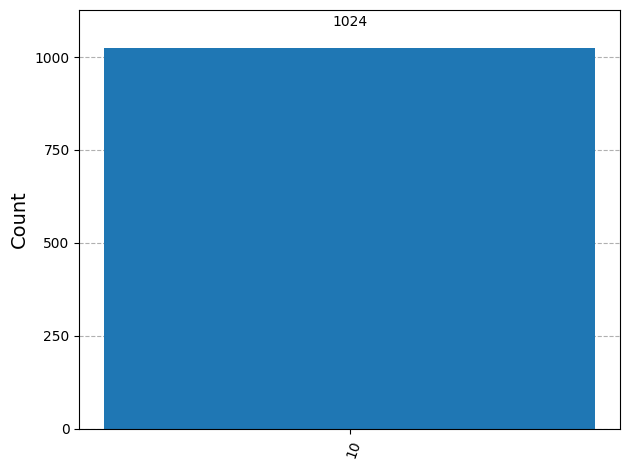

In [17]:
qasm_simulator = Aer.get_backend('qasm_simulator')

job = qasm_simulator.run(circ, shots=1024)

results = job.result()
answer = results.get_counts()
plot_histogram(answer)

We can also send our circuit to an actual quantum computer, using the API token from your IBM Quantum account (job will be run asynchronously but it may take some time):

In [46]:
# !!!! Remove before sending to the professor, to the one who does it !!!  
# This is paul's key
api_key = 'crisXNDBO6gELIjtija3JANTfIVtSzOXa-fyM7_02dvi'

In [19]:
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key)

backend = service.least_busy(operational=True, simulator=False)

print("Jobs will be running on %s" % backend.name)

Jobs will be running on ibm_torino


qiskit_runtime_service._discover_account:WARNING:2026-02-10 14:53:57,862: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-02-10 14:54:03,490: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-02-10 14:54:04,704: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-02-10 14:54:06,997: Using instance: open-instance, plan: open


In [20]:
# non-blocking, you may continue to evalue other cells

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
new_circuit = pm.run(circ)

sampler = Sampler(mode=backend)

job = sampler.run([new_circuit])

In [24]:
# check if job is done
print("Job ID: %s" % job.job_id())
print("Status: %s" % job.status())

Job ID: d65kd48qbmes739d10tg
Status: DONE


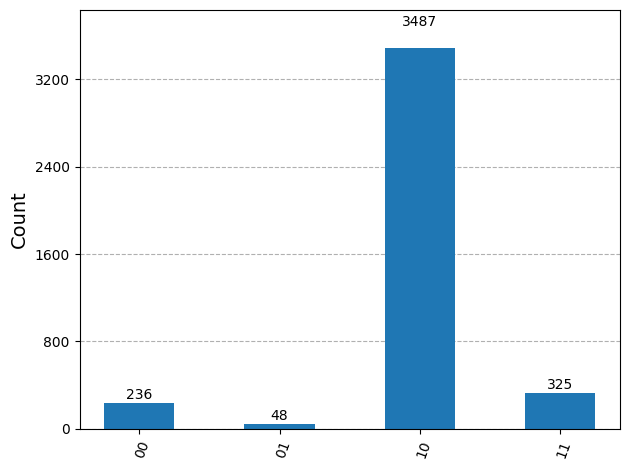

In [25]:
# waiting for the job to finish, however, *is* blocking, do not run until job is done
results = job.result()[0]
answer = results.data.meas.get_counts()
plot_histogram(answer)

Some (gate + measurement) errors are to be expected!

**To do**: Go through the same process again, this time looking for another element $\omega \in X$ of your choice.

We saw that running the program on real hardware corresponded to our expectations (with errors, like panned).  
We are then going to do the rest using the emulator like previously, that will permit us to get cleaner results.

Circuit for searching ω = 01:
        ┌───┐ ░               ░ ┌───┐┌───┐   ┌───┐┌───┐ ░  ░ ┌─┐   
   q_0: ┤ H ├─░───────■───────░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──░─┤M├───
        ├───┤ ░ ┌───┐ │ ┌───┐ ░ ├───┤├───┤ │ ├───┤├───┤ ░  ░ └╥┘┌─┐
   q_1: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──░──╫─┤M├
        └───┘ ░ └───┘   └───┘ ░ └───┘└───┘   └───┘└───┘ ░  ░  ║ └╥┘
meas: 2/══════════════════════════════════════════════════════╩══╩═
                                                              0  1 


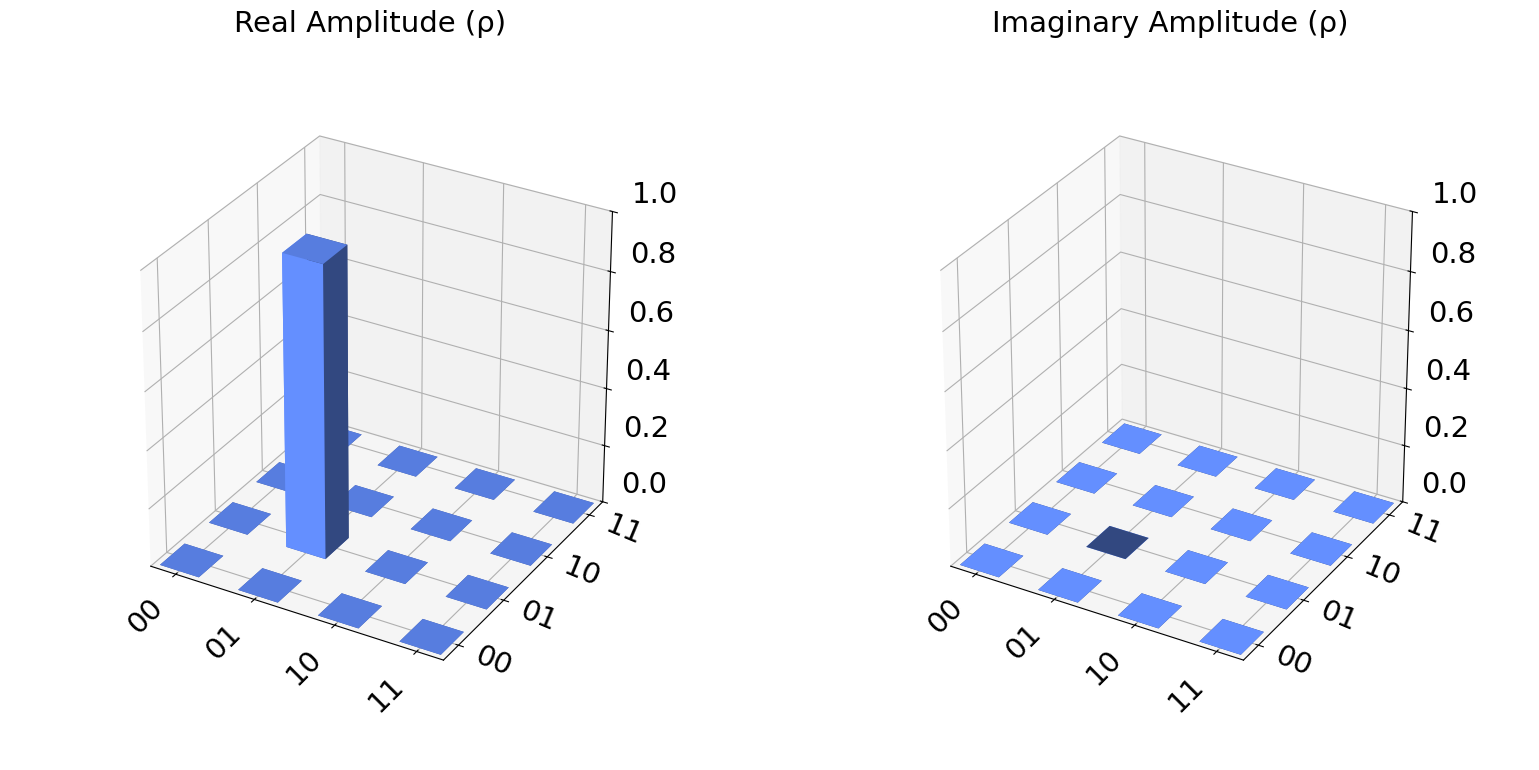

In [44]:
# We are gonna try to get the 01 element this time.

circ2 = QuantumCircuit(2)

full_h(circ2)
circ2.barrier()

# We try 01
# For 01: q_1=0, q_0=1, so we need X on q_1, CZ, then X on q_1 again
def oracle_01(qc):
    qc.x(1)
    qc.cz(0,1)
    qc.x(1)

oracle_01(circ2)
circ2.barrier()

g(circ2)
circ2.barrier()

# Measure
circ2.measure_all()
print("Circuit for searching ω = 01:")
print(circ2.draw())

state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ2)
answer = job.result().get_statevector()

plot_state_city(answer)

We get the value we wanted and programed for.  
Removing the both x gate from the oracle would give us 11 for example

## C) Grover with $N = 8$

**Todo**: a) Implement a Grover search on $n=3$ qubits for the state $\omega = 111$. Here the phase-flip $U_\omega$ oracle can be implemented as a controlled-controlled-$Z$ gate, constructed from a $CCX$ (Toffoli) gate and the fact that $Z = HXH$:

Grover circuit for searching ω = 111:
        ┌───┐ ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐      ░  ░ ┌─┐»
   q_0: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░──░─┤M├»
        ├───┤ ░        │        ░ ├───┤├───┤       │  ├───┤├───┤      ░  ░ └╥┘»
   q_1: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░──░──╫─»
        ├───┤ ░ ┌───┐┌─┴─┐┌───┐ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░  ░  ║ »
   q_2: ┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░──░──╫─»
        └───┘ ░ └───┘└───┘└───┘ ░ └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ░  ░  ║ »
meas: 3/════════════════════════════════════════════════════════════════════╩═»
                                                                            0 »
«              
«   q_0: ──────
«        ┌─┐   
«   q_1: ┤M├───
«        └╥┘┌─┐
«   q_2: ─╫─┤M├
«         ║ └╥┘
«meas: 3/═╩══╩═
«         1  2 


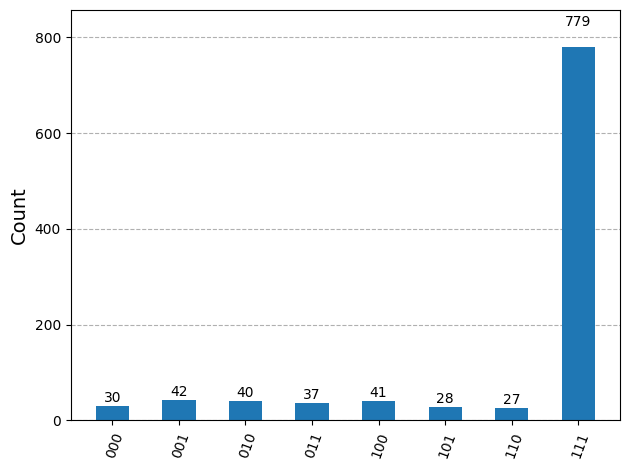

In [38]:
n = 3
target = '111'  # Searching for |111⟩

grover_circ = QuantumCircuit(n)

full_h(grover_circ)
grover_circ.barrier()

def oracle_111(qc):
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)  # multi-controlled Toffoli
    qc.h(n-1)
    qc.barrier()

oracle_111(grover_circ)

# Diffusion operator U_s (generalized for n=3)
def u_s(qc):
    full_h(qc)
    full_x(qc)
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)  # multi-controlled Toffoli for U_0
    qc.h(n-1)
    full_x(qc)
    full_h(qc)
    qc.barrier()

u_s(grover_circ)

# Measure all qubits
grover_circ.measure_all()

print("Grover circuit for searching ω = 111:")
print(grover_circ.draw())

# Simulate
qasm_simulator = Aer.get_backend('qasm_simulator')
job = qasm_simulator.run(grover_circ, shots=1024)
results = job.result()
answer = results.get_counts()
plot_histogram(answer)

You may experiment with different numbers $k$ of iterations of the amplitude amplification step $(G U_\omega)^k $ and compare with the optimal value predicted by theory.

Theoretical optimal iterations: 2.22 ≈ 2
k=1: Success probability for |111⟩ = 0.748
k=2: Success probability for |111⟩ = 0.946
k=3: Success probability for |111⟩ = 0.302
k=4: Success probability for |111⟩ = 0.009


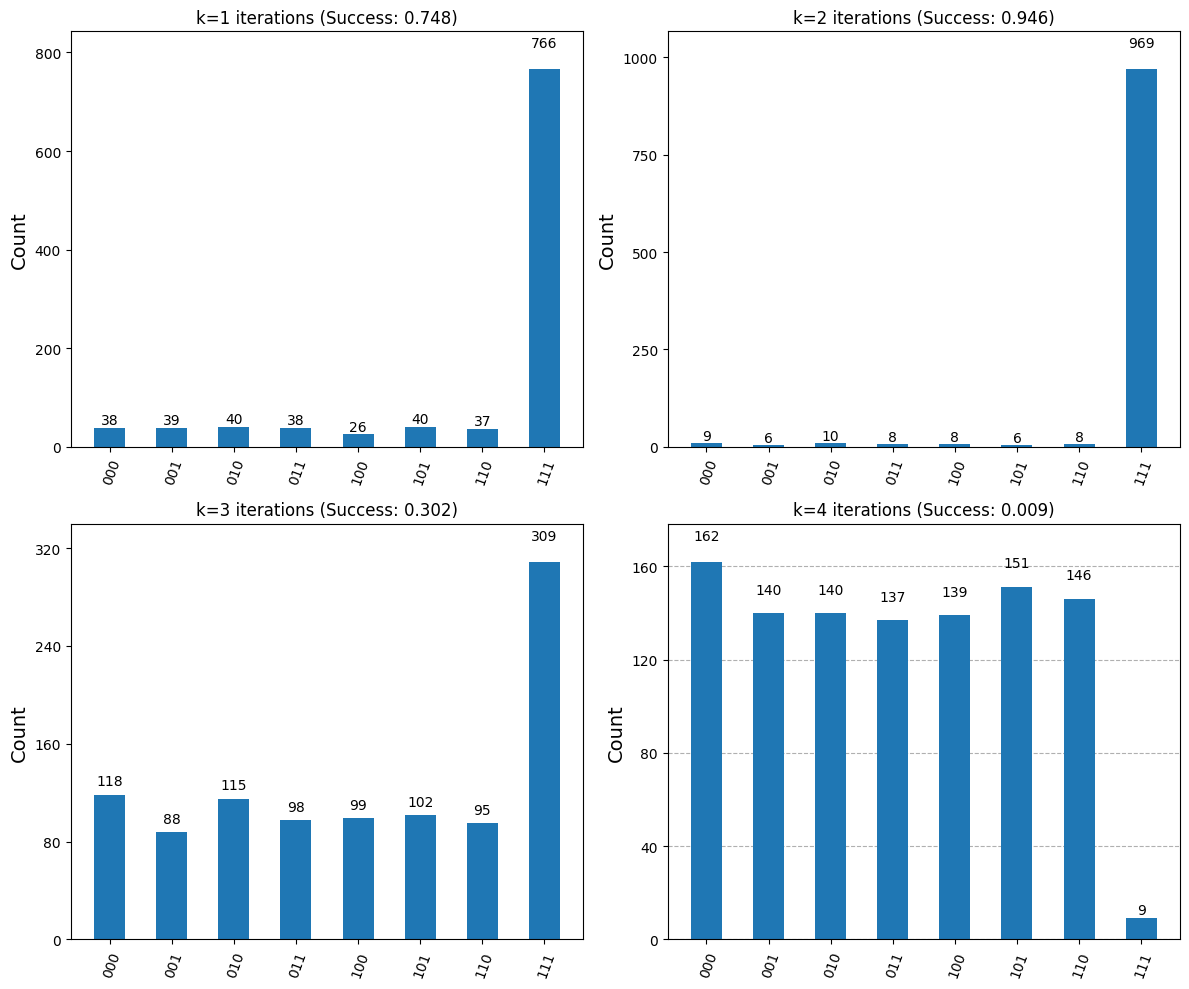

In [40]:
import numpy as np

def grover_iterations(n, iterations):
    """Run Grover's algorithm with specified number of iterations"""
    circ = QuantumCircuit(n)
    
    full_h(circ)
    circ.barrier()
    
    # Apply Grover iteration k times
    for _ in range(iterations):
        oracle_111(circ)
        u_s(circ)
    
    circ.measure_all()
    return circ


# Test different numbers of iterations
n = 3

# To find k, we simply divide the Total Angle needed (90°) by the Angle of one rotation.
optimal_k = int(np.round(np.pi / 4 * np.sqrt(2**n)))
print(f"Theoretical optimal iterations: {np.pi / 4 * np.sqrt(2**n):.2f} ≈ {optimal_k}")

# Test k = 1, 2, 3, 4 iterations
results_dict = {}
qasm_simulator = Aer.get_backend('qasm_simulator')

for k in range(1, 5):
    circ = grover_iterations(n, k)
    job = qasm_simulator.run(circ, shots=1024)
    counts = job.result().get_counts()
    success_prob = counts.get(target, 0) / 1024
    results_dict[k] = {'counts': counts, 'success_prob': success_prob}
    print(f"k={k}: Success probability for |{target}⟩ = {success_prob:.3f}")

# Plot comparison
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for idx, k in enumerate(range(1, 5)):
    ax = axes[idx // 2, idx % 2]
    plot_histogram(results_dict[k]['counts'], ax=ax)
    ax.set_title(f"k={k} iterations (Success: {results_dict[k]['success_prob']:.3f})")

plt.tight_layout()
plt.show()

The experiments show the same results as the theoretical value. 

b) Same question, but this time using the following phase-flip oracle: ![image.png](attachment:./aa.png) What is the optimal number of iterations this time? Can you explain what is happening?

Theoretical optimal iterations for 2 marked items: 1.57 ≈ 2
k=1: Success probability for |011⟩ or |111⟩ = 0.809
k=2: Success probability for |011⟩ or |111⟩ = 0.947
k=3: Success probability for |011⟩ or |111⟩ = 0.389
k=4: Success probability for |011⟩ or |111⟩ = 0.160


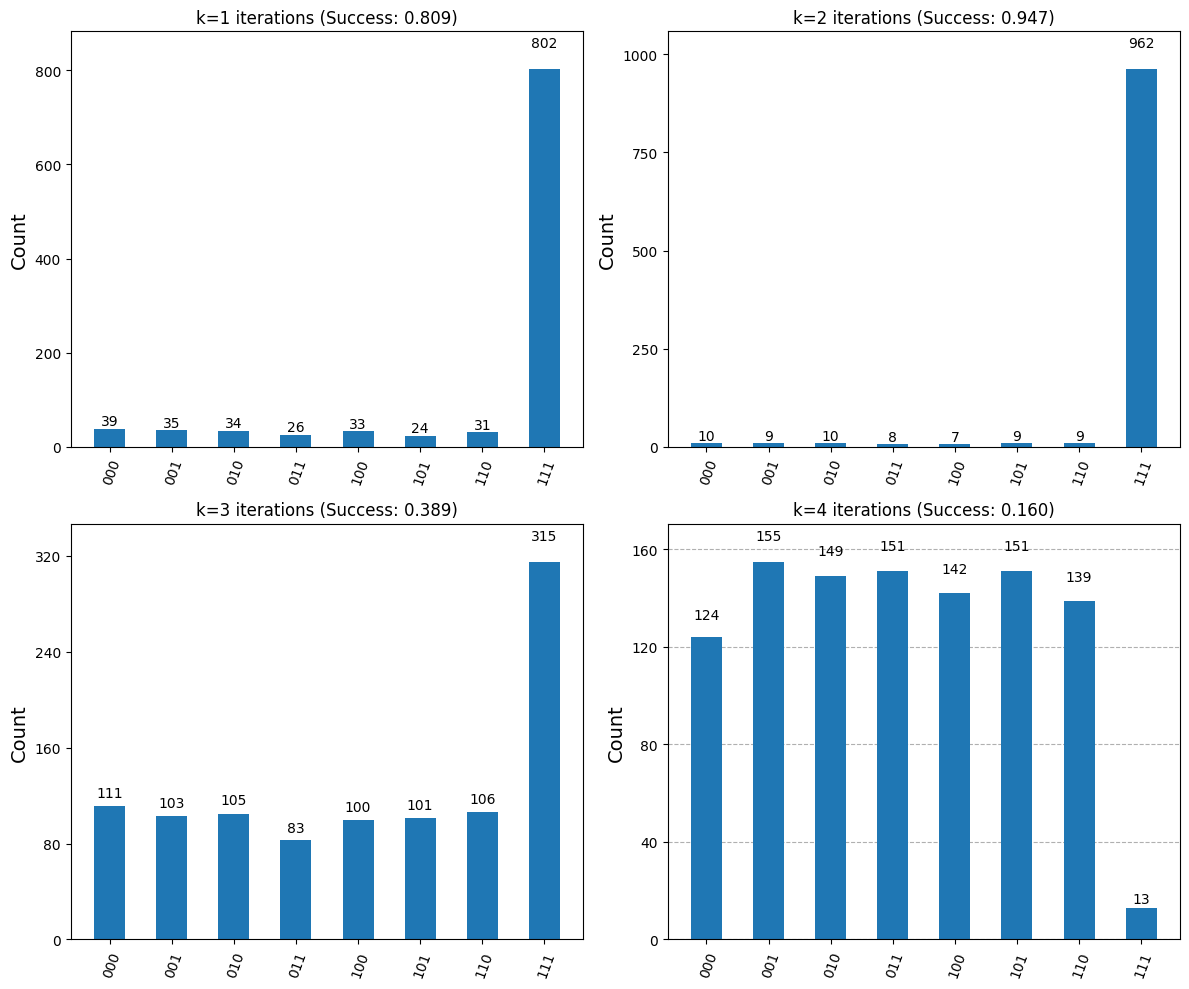

In [42]:
# Oracle that marks both |011⟩ and |111⟩ (when q₁=1 and q₀=1)
def oracle_two_items(qc):
    """Oracle that flips phase of |011⟩ and |111⟩"""
    # This is a CZ gate controlled on q₀ and q₁, applied to q₂
    qc.ccz(0, 1, 2)  # or equivalently: h(2), ccx(0,1,2), h(2)
    qc.barrier()

# We test same way as before
n = 3
marked_items = ['011', '111']
# it's pi/4*sqrt(2^n / 2) this time because we use two items
optimal_k_two = int(np.round(np.pi / 4 * np.sqrt(2**n / 2)))
print(f"Theoretical optimal iterations for 2 marked items: {np.pi / 4 * np.sqrt(2**n / 2):.2f} ≈ {optimal_k_two}")

results_two = {}
for k in range(1, 5):
    circ = QuantumCircuit(n)
    
    full_h(circ)
    circ.barrier()

    for _ in range(k):
        oracle_two_items(circ)
        
        u_s(circ)
    
    circ.measure_all()
    job = qasm_simulator.run(circ, shots=1024)
    counts = job.result().get_counts()
    
    # Calculate success probability (sum of both marked states)
    success_prob = sum(counts.get(item, 0) for item in marked_items) / 1024
    results_two[k] = {'counts': counts, 'success_prob': success_prob}
    print(f"k={k}: Success probability for |011⟩ or |111⟩ = {success_prob:.3f}")

# Plot results
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for idx, k in enumerate(range(1, 5)):
    ax = axes[idx // 2, idx % 2]
    plot_histogram(results_two[k]['counts'], ax=ax)
    ax.set_title(f"k={k} iterations (Success: {results_two[k]['success_prob']:.3f})")

plt.tight_layout()
plt.show()

Explanation: With 2 marked items instead of 1, the optimal number of iterations is reduced.
This is because the initial angle θ/2 is larger (more 'marked' probability mass), so fewer rotations are needed to reach the marked subspace.